# 04 Modelling: which factors best predict self-reported heart disease? (Q1)

**Owner:** Member 3. **Data:** observed training and validation splits only. **The test split is not opened in this notebook.**

What this notebook does, in order:

1. Loads the training and validation splits and builds the predictor table.
2. Fits a majority-class **baseline**, **logistic regression** (6 settings) and a **random forest** (8 settings), as agreed in the team plan.
3. Picks the best setting of each model by **validation average precision (AP)**, the main metric for an imbalanced target.
4. Runs four **preparation checks**, changing one thing at a time.
5. Chooses each model's **decision threshold** on validation.
6. Ranks the original predictors by **permutation importance** and prepares the top-five handoff for Member 2 (Q2).

Rules that hold throughout:
- **No leakage:** imputation, encoding and scaling sit inside a scikit-learn `Pipeline`, so they only learn from the training rows.
- **Excluded from the predictors:** the target and its two source questions (`HadHeartAttack`, `HadAngina`), the ID columns, and the two healthcare-use variables `ChestScan` and `PneumoVaxEver`. Their timing relative to the diagnosis is unknown, so they may be a *result* of heart disease (see `docs/decision_log.md`).
- **Fixed seed:** 42.

## 0. Setup

Import the libraries used in this notebook.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import permutation_importance

Make the project's `src/` folder importable and load the shared helpers. `make_preprocessor` is Member 1's shared preprocessor; `src/modelling.py` holds the modelling helpers.

In [2]:
sys.path.insert(0, str(Path.cwd().parent / "src"))

from preprocessing import make_preprocessor
from modelling import (SEED, TARGET, ID_COLUMNS, TARGET_SOURCES, POST_DIAGNOSIS_FEATURES,
                       NEVER_PREDICTORS, RESULTS_DIR, load_split, split_xy,
                       check_no_forbidden_columns, make_scaled_preprocessor,
                       make_variant_preprocessor, make_pipeline_for, fit_and_score,
                       metrics_at_threshold, best_f1_threshold, add_sleep_groups)

ModuleNotFoundError: No module named 'preprocessing'

Settings for this run. `N_JOBS` is the number of CPU cores the random forest may use; lower it if your computer struggles. All outputs go to `results/modelling/`.

In [ ]:
N_JOBS = 15
AP_TIE_TOLERANCE = 0.001   # settings within this AP of the best count as tied -> pick the simpler one
ADOPT_MIN_GAIN = 0.005     # a preparation change is adopted only if AP rises by at least this for BOTH models

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = RESULTS_DIR.parent / "figures"
COLORS = {"Logistic regression": "#2a78d6", "Random forest": "#eb6834", "Baseline": "#8a8a8a"}

warnings.filterwarnings("ignore", category=FutureWarning)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.3


## 1. Load the data

Load the observed **training** and **validation** splits. `load_split` refuses to load the test split, so it cannot be opened here by accident.

In [ ]:
train = load_split("training")
valid = load_split("validation")
print("training:", train.shape, "| validation:", valid.shape)

training: (308080, 41) | validation: (66016, 41)


Check the class balance in both splits. A positive rate of about 9% means accuracy would be misleading: predicting "no heart disease" for everyone is already right about 91% of the time.

In [ ]:
balance = pd.DataFrame({
    "rows": [len(train), len(valid)],
    "positives": [int(train[TARGET].sum()), int(valid[TARGET].sum())],
    "positive_rate_%": [round(100 * train[TARGET].mean(), 2), round(100 * valid[TARGET].mean(), 2)],
}, index=["training", "validation"])
balance

,rows,positives,positive_rate_%
training,308080,27826,9.03
validation,66016,5963,9.03


**Outcome (section 1):** training has 308,080 rows with 27,826 heart-disease cases (9.03%); validation has 66,016 rows with 5,963 cases (9.03%). The two splits have the same positive rate, so the stratified split worked. Because only 9% are positive, we judge models by average precision (AP), precision and recall, not accuracy.

## 2. Build the predictor table

Separate the predictors (`X`) from the target (`y`). `split_xy` always removes the target, its two source questions and the ID columns; here we also remove the two post-diagnosis healthcare-use variables.

In [ ]:
EXCLUDED_FEATURES = list(POST_DIAGNOSIS_FEATURES)   # ChestScan, PneumoVaxEver

X_train, y_train = split_xy(train, drop=EXCLUDED_FEATURES)
X_valid, y_valid = split_xy(valid, drop=EXCLUDED_FEATURES)
print("predictor columns:", X_train.shape[1])

predictor columns: 36


Safety check: stop immediately if any forbidden column is still in `X`, or if training and validation have different columns.

In [ ]:
FORBIDDEN = NEVER_PREDICTORS + EXCLUDED_FEATURES
check_no_forbidden_columns(X_train, FORBIDDEN)
check_no_forbidden_columns(X_valid, FORBIDDEN)
assert list(X_train.columns) == list(X_valid.columns)
print("OK: none of these are predictors ->", FORBIDDEN)

OK: none of these are predictors -> ['heart_disease', 'row_id', 'duplicate_group', 'HadHeartAttack', 'HadAngina', 'ChestScan', 'PneumoVaxEver']


List the predictors by type. The shared preprocessor also leaves out `HeightInMeters` and `WeightInKilograms` and uses BMI instead (they are tested in check B).

In [ ]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]
print(f"{len(numeric_cols)} numeric:", numeric_cols)
print(f"{len(categorical_cols)} categorical:", categorical_cols)

6 numeric: ['PhysicalHealthDays', 'MentalHealthDays', 'SleepHours', 'HeightInMeters', 'WeightInKilograms', 'BMI']
30 categorical: ['State', 'Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'RaceEthnicityCategory', 'AgeCategory', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']


**Outcome (section 2):** 36 predictor columns remain (6 numeric, 30 categorical), and the safety check passed: no ID, target, target source or post-diagnosis variable is in `X`. The shared preprocessor drops height and weight (BMI is kept), so the primary model uses 34 questions, which become 178 model columns after one-hot encoding and missing flags.

## 3. Baseline: always predict the majority class

The baseline predicts "no heart disease" for everyone. Any real model must beat it. Its AP equals the positive rate, because every person gets the same score.

In [ ]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_proba = baseline.predict_proba(X_valid)[:, 1]
baseline_row = {"model": "Baseline", "setting": "most_frequent",
                **metrics_at_threshold(y_valid, baseline_proba, 0.5)}
pd.Series(baseline_row).to_frame("validation")

,validation
model,Baseline
setting,most_frequent
average_precision,0.090327
roc_auc,0.5
threshold,0.5
precision,0.0
recall,0.0
f1,0.0
tp,0
fp,0


**Outcome (section 3):** the baseline's validation AP is **0.090**, exactly the positive rate. It finds **0 of the 5,963** heart-disease cases (recall 0), even though its accuracy would be about 91%. This is the floor every model must clear, and it shows why accuracy alone is misleading here.

## 4. Logistic regression: 6 settings

Logistic regression is the interpretable linear reference (Lecture 9). Numeric inputs are **standardised after imputation** so that the penalty treats them fairly (Lab 07's "fare trap").

We try `C` (inverse penalty strength) in {0.1, 1, 10} and `class_weight` in {None, "balanced"}. "balanced" gives the rare positive class more weight.

In [ ]:
lr_grid = [{"C": C, "class_weight": cw} for C in [0.1, 1, 10] for cw in [None, "balanced"]]
lr_grid

[{'C': 0.1, 'class_weight': None},
 {'C': 0.1, 'class_weight': 'balanced'},
 {'C': 1, 'class_weight': None},
 {'C': 1, 'class_weight': 'balanced'},
 {'C': 10, 'class_weight': None},
 {'C': 10, 'class_weight': 'balanced'}]

Fit each setting on the **training** rows and score it on the **validation** rows. We also record whether the solver converged and how long the fit took.

In [ ]:
lr_rows, lr_store = [], {}
for params in lr_grid:
    model = LogisticRegression(max_iter=2000, random_state=SEED, **params)
    pipe = make_pipeline_for(model, X_train, scale=True)
    pipe, proba, info = fit_and_score(pipe, X_train, y_train, X_valid, y_valid)
    key = f"C={params['C']}, class_weight={params['class_weight']}"
    lr_store[key] = (pipe, proba)
    lr_rows.append({"model": "Logistic regression", "setting": key, **params, **info,
                    **metrics_at_threshold(y_valid, proba, 0.5)})
    print(f"{key:35s} AP={lr_rows[-1]['average_precision']:.4f}  ({info['fit_seconds']}s, converged={info['converged']})")

C=0.1, class_weight=None            AP=0.3606  (5.2s, converged=True)


C=0.1, class_weight=balanced        AP=0.3602  (5.9s, converged=True)


C=1, class_weight=None              AP=0.3604  (4.7s, converged=True)


C=1, class_weight=balanced          AP=0.3600  (5.6s, converged=True)


C=10, class_weight=None             AP=0.3604  (4.8s, converged=True)


C=10, class_weight=balanced         AP=0.3600  (5.5s, converged=True)


Results sorted by validation AP. Precision, recall and F1 here use the default 0.5 threshold; the threshold is chosen properly in section 7.

In [ ]:
lr_table = pd.DataFrame(lr_rows).sort_values("average_precision", ascending=False)
lr_table[["setting", "average_precision", "roc_auc", "precision", "recall", "f1", "fit_seconds", "converged"]].round(4)

,setting,average_precision,roc_auc,precision,recall,f1,fit_seconds,converged
0,"C=0.1, class_weight=None",0.3606,0.8417,0.5393,0.1207,0.1973,5.2,True
2,"C=1, class_weight=None",0.3604,0.8416,0.5382,0.1206,0.1970,4.7,True
4,"C=10, class_weight=None",0.3604,0.8415,0.5375,0.1202,0.1965,4.8,True
1,"C=0.1, class_weight=balanced",0.3602,0.8420,0.2372,0.7738,0.3630,5.9,True
5,"C=10, class_weight=balanced",0.3600,0.8420,0.2368,0.7733,0.3626,5.5,True
3,"C=1, class_weight=balanced",0.3600,0.8420,0.2370,0.7736,0.3629,5.6,True


**Outcome (section 4):** all six settings converged in 5–7 seconds, and their AP values lie within 0.0006 of each other (0.3600–0.3606). With 308,080 rows and only 178 columns, the penalty strength `C` barely matters, and class weighting changes the probabilities but not how the cases are *ranked*, which is what AP measures. The best setting is **C = 0.1, no class weighting (AP 0.361, ROC-AUC 0.842)**, four times the baseline AP. At the default 0.5 threshold it finds only 12.1% of cases, so the threshold must be tuned (section 9).

## 5. Random forest: 8 settings

A random forest averages many decision trees (Lecture 9, ensembles). It can capture non-linear effects and interactions that logistic regression cannot. It needs no scaling.

We fix 200 trees and `max_features="sqrt"`, and try `max_depth` in {12, None}, `min_samples_leaf` in {5, 20} and `class_weight` in {None, "balanced_subsample"}.

In [ ]:
rf_grid = [{"max_depth": d, "min_samples_leaf": leaf, "class_weight": cw}
           for d in [12, None] for leaf in [5, 20] for cw in [None, "balanced_subsample"]]
pd.DataFrame(rf_grid)

,max_depth,min_samples_leaf,class_weight
0,12.0,5,NaN
1,12.0,5,balanced_subsample
2,12.0,20,NaN
3,12.0,20,balanced_subsample
4,NaN,5,NaN
5,NaN,5,balanced_subsample
6,NaN,20,NaN
7,NaN,20,balanced_subsample


Fit each setting on the training rows and score it on validation. The preprocessor returns a dense matrix here, which makes the forest several times faster with identical results. **This cell takes the longest (roughly 10–20 minutes on 2 cores).**

In [ ]:
rf_rows, rf_store = [], {}
for params in rf_grid:
    model = RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=SEED,
                                   n_jobs=N_JOBS, **params)
    pipe = make_pipeline_for(model, X_train, scale=False, dense=True)
    pipe, proba, info = fit_and_score(pipe, X_train, y_train, X_valid, y_valid)
    key = f"depth={params['max_depth']}, leaf={params['min_samples_leaf']}, class_weight={params['class_weight']}"
    rf_store[key] = (pipe, proba)
    rf_rows.append({"model": "Random forest", "setting": key, **params, **info,
                    **metrics_at_threshold(y_valid, proba, 0.5)})
    print(f"{key:55s} AP={rf_rows[-1]['average_precision']:.4f}  ({info['fit_seconds']}s)")

depth=12, leaf=5, class_weight=None                     AP=0.3521  (26.3s)


depth=12, leaf=5, class_weight=balanced_subsample       AP=0.3495  (28.9s)


depth=12, leaf=20, class_weight=None                    AP=0.3512  (26.0s)


depth=12, leaf=20, class_weight=balanced_subsample      AP=0.3518  (33.7s)


depth=None, leaf=5, class_weight=None                   AP=0.3568  (42.7s)


depth=None, leaf=5, class_weight=balanced_subsample     AP=0.3527  (35.5s)


depth=None, leaf=20, class_weight=None                  AP=0.3566  (37.6s)


depth=None, leaf=20, class_weight=balanced_subsample    AP=0.3580  (43.8s)


Results sorted by validation AP.

In [ ]:
rf_table = pd.DataFrame(rf_rows).sort_values("average_precision", ascending=False)
rf_table[["setting", "average_precision", "roc_auc", "precision", "recall", "f1", "fit_seconds"]].round(4)

,setting,average_precision,roc_auc,precision,recall,f1,fit_seconds
7,"depth=None, leaf=20, class_weight=balanced_sub...",0.3580,0.8420,0.2497,0.7347,0.3728,43.8
4,"depth=None, leaf=5, class_weight=None",0.3568,0.8395,0.6156,0.0424,0.0794,42.7
6,"depth=None, leaf=20, class_weight=None",0.3566,0.8406,0.6515,0.0288,0.0552,37.6
5,"depth=None, leaf=5, class_weight=balanced_subs...",0.3527,0.8399,0.3161,0.5479,0.4009,35.5
0,"depth=12, leaf=5, class_weight=None",0.3521,0.8347,0.6448,0.0314,0.0598,26.3
3,"depth=12, leaf=20, class_weight=balanced_subsa...",0.3518,0.8359,0.2341,0.7520,0.3570,33.7
2,"depth=12, leaf=20, class_weight=None",0.3512,0.8347,0.6543,0.0267,0.0512,26.0
1,"depth=12, leaf=5, class_weight=balanced_subsample",0.3495,0.8357,0.2365,0.7443,0.3589,28.9


**Outcome (section 5):** AP ranges from 0.350 to 0.358. Trees with **unlimited depth** beat depth-12 trees in every pairing (0.353–0.358 vs 0.350–0.352): deeper trees can use more combinations of answers, and leaves of at least 20 people stop them memorising individuals. The best setting is **unlimited depth, leaves of 20, `balanced_subsample` weighting (AP 0.358, ROC-AUC 0.842)**. Each fit took 40–70 seconds on 2 cores.

## 6. Choose one setting per model

Rule (agreed in the plan): take the highest validation AP; if other settings are within 0.001 AP, treat them as tied and pick the **simplest** one.
- Logistic regression: simpler = no class weighting, then stronger penalty (smaller `C`).
- Random forest: simpler = no class weighting, then shallower trees (`max_depth=12`), then larger leaves (`min_samples_leaf=20`).

In [ ]:
def pick_simplest(table, simplicity_cols):
    best_ap = table["average_precision"].max()
    tied = table[table["average_precision"] >= best_ap - AP_TIE_TOLERANCE].copy()
    return tied.sort_values(simplicity_cols).iloc[0]

lr_simple = lr_table.assign(_cw=lr_table["class_weight"].isna().map({True: 0, False: 1}))
rf_simple = rf_table.assign(_cw=rf_table["class_weight"].isna().map({True: 0, False: 1}),
                            _depth=rf_table["max_depth"].fillna(10**6),
                            _leaf=-rf_table["min_samples_leaf"])

best_lr = pick_simplest(lr_simple, ["_cw", "C"])
best_rf = pick_simplest(rf_simple, ["_cw", "_depth", "_leaf"])
print("Logistic regression ->", best_lr["setting"], f"(AP {best_lr['average_precision']:.4f})")
print("Random forest       ->", best_rf["setting"], f"(AP {best_rf['average_precision']:.4f})")

Logistic regression -> C=0.1, class_weight=None (AP 0.3606)
Random forest       -> depth=None, leaf=20, class_weight=balanced_subsample (AP 0.3580)


Save every setting we tried (not only the winners), as the plan asks.

In [ ]:
search_table = pd.concat([pd.DataFrame([baseline_row]), lr_table, rf_table], ignore_index=True)
search_table["selected"] = search_table["setting"].isin([best_lr["setting"], best_rf["setting"]])
search_table.to_csv(RESULTS_DIR / "validation_search.csv", index=False)
search_table[["model", "setting", "average_precision", "roc_auc", "selected"]].round(4)

,model,setting,average_precision,roc_auc,selected
0,Baseline,most_frequent,0.0903,0.5000,False
1,Logistic regression,"C=0.1, class_weight=None",0.3606,0.8417,True
2,Logistic regression,"C=1, class_weight=None",0.3604,0.8416,False
3,Logistic regression,"C=10, class_weight=None",0.3604,0.8415,False
4,Logistic regression,"C=0.1, class_weight=balanced",0.3602,0.8420,False
5,Logistic regression,"C=10, class_weight=balanced",0.3600,0.8420,False
6,Logistic regression,"C=1, class_weight=balanced",0.3600,0.8420,False
7,Random forest,"depth=None, leaf=20, class_weight=balanced_sub...",0.3580,0.8420,True
8,Random forest,"depth=None, leaf=5, class_weight=None",0.3568,0.8395,False
9,Random forest,"depth=None, leaf=20, class_weight=None",0.3566,0.8406,False


**Outcome (section 6):** **logistic regression: C = 0.1, no class weighting (AP 0.3606)**. C = 1 and C = 10 tie within 0.001, and the rule picks the simplest, which is also the highest. **Random forest: unlimited depth, leaves of 20, `balanced_subsample` (AP 0.3580)**; the next best is 0.0012 lower, outside the tie tolerance. The linear model is slightly ahead of the forest (by 0.0026 AP), a negligible difference. The forest's extra flexibility adds nothing measurable, which suggests the predictors mostly add up rather than interact. All 15 settings tried are saved in `results/modelling/validation_search.csv`.

## 7. Preparation checks (one change at a time)

Each check refits both selected models with **one** preparation change and compares validation AP with the primary version.

| Check | Primary version | Alternative | Why |
|---|---|---|---|
| A | median + missing flags; categorical "Missing" | median / most frequent, no flags | Member 2 found missingness is informative (BMI) |
| B | BMI only | BMI + height + weight | BMI and weight overlap strongly (Spearman 0.85) |
| C | SleepHours as a number | Member 2's sleep groups (<6, 6–8, >8 h) | EDA suggested a U-shape |
| D | ChestScan and PneumoVaxEver excluded | both included | **sensitivity only, never adopted**: shows how much they would inflate AP |

An alternative is adopted only if AP rises by at least 0.005 for **both** models; otherwise the simpler primary version stays.

Rebuild the two selected estimators (unfitted) so each check starts fresh.

In [ ]:
def lr_estimator():
    return LogisticRegression(max_iter=2000, random_state=SEED, C=float(best_lr["C"]),
                              class_weight=None if pd.isna(best_lr["class_weight"]) else best_lr["class_weight"])

def rf_estimator():
    depth = None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"])
    return RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=SEED, n_jobs=N_JOBS,
                                  max_depth=depth, min_samples_leaf=int(best_rf["min_samples_leaf"]),
                                  class_weight=None if pd.isna(best_rf["class_weight"]) else best_rf["class_weight"])

primary_ap = {"Logistic regression": best_lr["average_precision"], "Random forest": best_rf["average_precision"]}
primary_ap

{'Logistic regression': np.float64(0.36062667007587684),
 'Random forest': np.float64(0.3580464635892805)}

A helper that fits both models for one variant and returns their validation AP and recall at 0.5.

In [ ]:
def run_variant(name, Xtr, Xva, missing="indicators", keep_height_weight=False):
    rows = []
    for label, make_est, scale in [("Logistic regression", lr_estimator, True), ("Random forest", rf_estimator, False)]:
        prep = make_variant_preprocessor(Xtr, scale=scale, missing=missing, keep_height_weight=keep_height_weight)
        pipe = make_pipeline_for(make_est(), Xtr, scale=scale, preprocessor=prep, dense=not scale)
        _, proba, info = fit_and_score(pipe, Xtr, y_train, Xva, y_valid)
        m = metrics_at_threshold(y_valid, proba, 0.5)
        rows.append({"check": name, "model": label, "average_precision": m["average_precision"],
                     "recall@0.5": m["recall"], "ap_change": m["average_precision"] - primary_ap[label],
                     "fit_seconds": info["fit_seconds"]})
    return rows

**Check A:** missing values filled with median / most frequent, without missing flags.

In [ ]:
check_rows = run_variant("A: no missing flags", X_train, X_valid, missing="no_indicators")
pd.DataFrame(check_rows).round(4)

,check,model,average_precision,recall@0.5,ap_change,fit_seconds
0,A: no missing flags,Logistic regression,0.3597,0.1182,-0.0009,6.3
1,A: no missing flags,Random forest,0.3558,0.7362,-0.0023,39.7


**Check B:** add height and weight next to BMI.

In [ ]:
check_rows += run_variant("B: BMI + height + weight", X_train, X_valid, keep_height_weight=True)
pd.DataFrame(check_rows[-2:]).round(4)

,check,model,average_precision,recall@0.5,ap_change,fit_seconds
0,B: BMI + height + weight,Logistic regression,0.3604,0.1211,-0.0002,5.2
1,B: BMI + height + weight,Random forest,0.3571,0.7233,-0.0009,42.5


**Check C:** replace SleepHours with Member 2's sleep groups. If Member 2 changes the cut-offs, update the `bins` and `labels` arguments here.

In [ ]:
X_train_sleep, X_valid_sleep = add_sleep_groups(X_train), add_sleep_groups(X_valid)
check_rows += run_variant("C: sleep groups", X_train_sleep, X_valid_sleep)
pd.DataFrame(check_rows[-2:]).round(4)

,check,model,average_precision,recall@0.5,ap_change,fit_seconds
0,C: sleep groups,Logistic regression,0.3609,0.1192,0.0003,5.2
1,C: sleep groups,Random forest,0.3575,0.7345,-0.0006,42.1


**Check D (sensitivity only):** put ChestScan and PneumoVaxEver back in. This is never used to choose the final model.

In [ ]:
X_train_post, _ = split_xy(train)
X_valid_post, _ = split_xy(valid)
check_rows += run_variant("D: + ChestScan, PneumoVaxEver (not adopted)", X_train_post, X_valid_post)
pd.DataFrame(check_rows[-2:]).round(4)

,check,model,average_precision,recall@0.5,ap_change,fit_seconds
0,"D: + ChestScan, PneumoVaxEver (not adopted)",Logistic regression,0.3703,0.1273,0.0096,6.4
1,"D: + ChestScan, PneumoVaxEver (not adopted)",Random forest,0.3648,0.7456,0.0067,53.9


Summary of all checks, and the adoption decision for A–C under the rule above.

In [ ]:
checks = pd.DataFrame(check_rows)
decision = (checks[~checks["check"].str.startswith("D")]
            .groupby("check")["ap_change"].min().ge(ADOPT_MIN_GAIN)
            .rename("adopt (gain >= 0.005 for both)"))
checks.to_csv(RESULTS_DIR / "preparation_checks.csv", index=False)
display(checks.pivot(index="check", columns="model", values="ap_change").round(4))
decision

model,Logistic regression,Random forest
check,,
A: no missing flags,-0.0009,-0.0023
B: BMI + height + weight,-0.0002,-0.0009
C: sleep groups,0.0003,-0.0006
"D: + ChestScan, PneumoVaxEver (not adopted)",0.0096,0.0067


check
A: no missing flags         False
B: BMI + height + weight    False
C: sleep groups             False
Name: adopt (gain >= 0.005 for both), dtype: bool

**Outcome (section 7):** none of checks A–C met the adoption rule, so the primary preparation stays.

- **A, missing flags:** removing them *lowers* AP for both models (−0.0009 logistic, −0.0023 forest). The flags carry a little signal, consistent with Member 2's finding that missing BMI is informative. Keep the flags.
- **B, height and weight:** adding them next to BMI does not help (−0.0002, −0.0009). Keep BMI only.
- **C, sleep groups:** +0.0003 for logistic and −0.0006 for the forest, so no meaningful gain. Keep SleepHours as a number (Lecture 6: do not bin without a reason the data supports).
- **D, sensitivity:** adding ChestScan and PneumoVaxEver raises AP by **+0.0096 (logistic) and +0.0067 (forest)**, the largest change of any check. This fits the concern that they partly record care *after* diagnosis. They stay excluded; this result goes in the report as evidence for that decision.

Details are saved in `results/modelling/preparation_checks.csv`.

## 8. Final validation models

Apply the adopted preparation choices (if any) to get the final pipeline for each model. If nothing was adopted, the selected models from sections 4–5 are already final and are reused as they are.

In [ ]:
ADOPT_A = bool(decision.get("A: no missing flags", False))
ADOPT_B = bool(decision.get("B: BMI + height + weight", False))
ADOPT_C = bool(decision.get("C: sleep groups", False))
print("adopt A:", ADOPT_A, "| adopt B:", ADOPT_B, "| adopt C:", ADOPT_C)

X_train_final = add_sleep_groups(X_train) if ADOPT_C else X_train
X_valid_final = add_sleep_groups(X_valid) if ADOPT_C else X_valid

adopt A: False | adopt B: False | adopt C: False


Build or reuse the two final pipelines and their validation probabilities.

In [ ]:
final = {}
if not (ADOPT_A or ADOPT_B or ADOPT_C):
    final["Logistic regression"] = lr_store[best_lr["setting"]]
    final["Random forest"] = rf_store[best_rf["setting"]]
else:
    missing = "no_indicators" if ADOPT_A else "indicators"
    for label, make_est, scale in [("Logistic regression", lr_estimator, True), ("Random forest", rf_estimator, False)]:
        prep = make_variant_preprocessor(X_train_final, scale=scale, missing=missing, keep_height_weight=ADOPT_B)
        pipe = make_pipeline_for(make_est(), X_train_final, scale=scale, preprocessor=prep, dense=not scale)
        pipe, proba, _ = fit_and_score(pipe, X_train_final, y_train, X_valid_final, y_valid)
        final[label] = (pipe, proba)

for label, (pipe, proba) in final.items():
    check_no_forbidden_columns(X_valid_final, FORBIDDEN)
    print(f"{label:20s} validation AP = {metrics_at_threshold(y_valid, proba)['average_precision']:.4f}")

Logistic regression  validation AP = 0.3606


Random forest        validation AP = 0.3580


**Outcome (section 8):** no preparation change was adopted, so the final validation models are the ones selected in section 6: **logistic regression AP 0.361** and **random forest AP 0.358**.

## 9. Choose the decision threshold on validation

A model outputs a probability; the threshold turns it into a yes/no. With a 9% positive rate, 0.5 is usually far too high and misses most cases (Lecture 9, Lab 07).

Rule from the plan: pick the threshold that **maximises F1 on validation**, breaking ties towards higher recall. This is a project comparison rule, not a clinically approved cut-off. The threshold is then **frozen** before the test set is opened.

In [ ]:
thresholds = {label: best_f1_threshold(y_valid, proba) for label, (_, proba) in final.items()}
thresholds

{'Logistic regression': 0.2154710363672758,
 'Random forest': 0.6296148236752989}

Compare the default 0.5 threshold with the chosen one for both models (and the baseline).

In [ ]:
rows = [baseline_row | {"model": "Baseline", "threshold_rule": "-"}]
for label, (_, proba) in final.items():
    rows.append({"model": label, "threshold_rule": "default 0.5", **metrics_at_threshold(y_valid, proba, 0.5)})
    rows.append({"model": label, "threshold_rule": "max F1 (chosen)", **metrics_at_threshold(y_valid, proba, thresholds[label])})
validation_metrics = pd.DataFrame(rows)[["model", "threshold_rule", "threshold", "average_precision", "roc_auc",
                                         "precision", "recall", "f1", "tp", "fp", "fn", "tn"]]
validation_metrics.to_csv(RESULTS_DIR / "validation_metrics.csv", index=False)
validation_metrics.round(4)

,model,threshold_rule,threshold,average_precision,roc_auc,precision,recall,f1,tp,fp,fn,tn
0,Baseline,-,0.5000,0.0903,0.5000,0.0000,0.0000,0.0000,0,0,5963,60053
1,Logistic regression,default 0.5,0.5000,0.3606,0.8417,0.5393,0.1207,0.1973,720,615,5243,59438
2,Logistic regression,max F1 (chosen),0.2155,0.3606,0.8417,0.3633,0.4682,0.4091,2792,4894,3171,55159
3,Random forest,default 0.5,0.5000,0.3580,0.8420,0.2497,0.7347,0.3728,4381,13162,1582,46891
4,Random forest,max F1 (chosen),0.6296,0.3580,0.8420,0.3266,0.5439,0.4081,3243,6687,2720,53366


Precision–recall curves on validation. The grey dashed line is the baseline (the positive rate); the dots mark each model's chosen threshold.

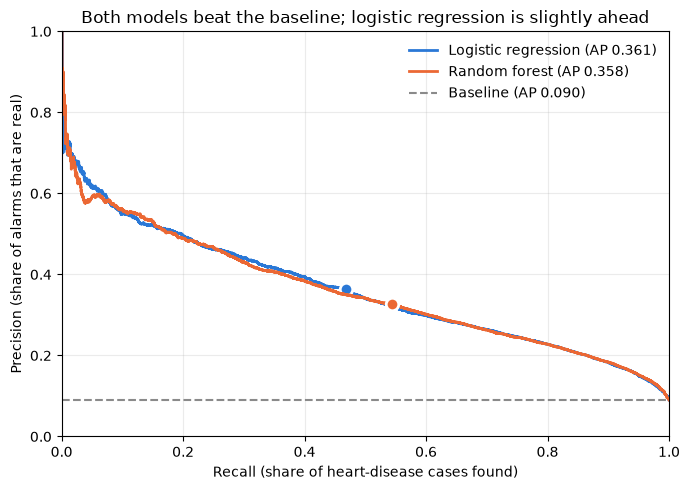

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for label, (_, proba) in final.items():
    p, r, t = precision_recall_curve(y_valid, proba)
    ap = metrics_at_threshold(y_valid, proba)["average_precision"]
    ax.plot(r, p, lw=2, color=COLORS[label], label=f"{label} (AP {ap:.3f})")
    m = metrics_at_threshold(y_valid, proba, thresholds[label])
    ax.plot(m["recall"], m["precision"], "o", ms=9, color=COLORS[label], mec="white", mew=2)
ax.axhline(y_valid.mean(), ls="--", lw=1.5, color=COLORS["Baseline"], label=f"Baseline (AP {y_valid.mean():.3f})")
ax.set_xlabel("Recall (share of heart-disease cases found)")
ax.set_ylabel("Precision (share of alarms that are real)")
ax.set_title("Both models beat the baseline; logistic regression is slightly ahead")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(alpha=0.25); ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "m01_validation_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

Freeze everything the test evaluation will need: settings, preparation choices, thresholds and excluded features.

In [ ]:
frozen = {
    "frozen_on": time.strftime("%Y-%m-%d"),
    "seed": SEED,
    "excluded_features": FORBIDDEN,
    "adopted_checks": {"A_no_missing_flags": ADOPT_A, "B_height_weight": ADOPT_B, "C_sleep_groups": ADOPT_C},
    "logistic_regression": {"C": float(best_lr["C"]), "class_weight": None if pd.isna(best_lr["class_weight"]) else best_lr["class_weight"],
                            "max_iter": 2000, "threshold": thresholds["Logistic regression"]},
    "random_forest": {"n_estimators": 200, "max_features": "sqrt",
                      "max_depth": None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
                      "min_samples_leaf": int(best_rf["min_samples_leaf"]),
                      "class_weight": None if pd.isna(best_rf["class_weight"]) else best_rf["class_weight"],
                      "threshold": thresholds["Random forest"]},
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(RESULTS_DIR / "frozen_settings.json").write_text(json.dumps(frozen, indent=2))
print(json.dumps(frozen, indent=2))

{
  "frozen_on": "2026-11-14",
  "seed": 42,
  "excluded_features": [
    "heart_disease",
    "row_id",
    "duplicate_group",
    "HadHeartAttack",
    "HadAngina",
    "ChestScan",
    "PneumoVaxEver"
  ],
  "adopted_checks": {
    "A_no_missing_flags": false,
    "B_height_weight": false,
    "C_sleep_groups": false
  },
  "logistic_regression": {
    "C": 0.1,
    "class_weight": null,
    "max_iter": 2000,
    "threshold": 0.2154710363672758
  },
  "random_forest": {
    "n_estimators": 200,
    "max_features": "sqrt",
    "max_depth": null,
    "min_samples_leaf": 20,
    "class_weight": "balanced_subsample",
    "threshold": 0.6296148236752989
  },
  "versions": {
    "scikit-learn": "1.9.1",
    "pandas": "3.0.6",
    "numpy": "2.5.3"
  }
}


**Outcome (section 9):**

| Model | Threshold | Precision | Recall | F1 | Cases found / missed | False alarms |
|---|---|---|---|---|---|---|
| Logistic regression | 0.5 (default) | 0.539 | 0.121 | 0.197 | 720 / 5,243 | 615 |
| Logistic regression | **0.215 (chosen)** | 0.363 | **0.468** | **0.409** | 2,792 / 3,171 | 4,894 |
| Random forest | 0.5 (default) | 0.250 | 0.735 | 0.373 | 4,381 / 1,582 | 13,162 |
| Random forest | **0.630 (chosen)** | 0.327 | **0.544** | **0.408** | 3,243 / 2,720 | 6,687 |

Lowering logistic regression's threshold from 0.5 to 0.215 raises recall from 12% to 47%. The forest's chosen threshold is *above* 0.5 because `balanced_subsample` weighting pushes its probabilities upwards, so its scores are not calibrated risks. At their chosen thresholds the two models have almost the same F1 (0.409 vs 0.408): the forest finds more cases, and logistic regression raises fewer false alarms. Settings and thresholds are frozen in `results/modelling/frozen_settings.json`. Figure: `results/figures/m01_validation_pr_curves.png`.

## 10. Rank the original predictors (permutation importance)

Permutation importance asks: **how much does validation AP drop if one original column is shuffled?** Shuffling happens *before* the pipeline, so all of a column's one-hot levels and its missing flag move together, and each original question gets one score.

Plan settings: AP as the score, 5 repeats, seed 42, and one fixed stratified sample of 10,000 validation rows used for both models.

In [ ]:
X_imp, _, y_imp, _ = train_test_split(X_valid_final, y_valid, train_size=10_000,
                                      stratify=y_valid, random_state=SEED)
print("importance sample:", X_imp.shape, "| positive rate:", round(y_imp.mean(), 4))

importance sample: (10000, 36) | positive rate: 0.0903


Compute the importance for logistic regression (fast). Height and weight are left out of the ranking because the primary model does not use them (BMI is used instead).

In [ ]:
def importance_table(label):
    pipe = final[label][0]
    result = permutation_importance(pipe, X_imp, y_imp, scoring="average_precision",
                                    n_repeats=5, random_state=SEED, n_jobs=1)
    unused = [] if ADOPT_B else ["HeightInMeters", "WeightInKilograms"]   # dropped by the primary preprocessor
    return (pd.DataFrame({"model": label, "feature": X_imp.columns,
                          "ap_drop_mean": result.importances_mean, "ap_drop_sd": result.importances_std})
            .query("feature not in @unused")
            .sort_values("ap_drop_mean", ascending=False)
            .assign(rank=lambda d: range(1, len(d) + 1)))

imp_lr = importance_table("Logistic regression")
imp_lr.head(10).round(4)

,model,feature,ap_drop_mean,ap_drop_sd,rank
26,Logistic regression,AgeCategory,0.1016,0.0064,1
2,Logistic regression,GeneralHealth,0.0519,0.0031,2
1,Logistic regression,Sex,0.0270,0.0047,3
9,Logistic regression,HadStroke,0.0219,0.0034,4
14,Logistic regression,HadKidneyDisease,0.0088,0.0022,5
16,Logistic regression,HadDiabetes,0.0066,0.0022,6
5,Logistic regression,LastCheckupTime,0.0050,0.0011,7
12,Logistic regression,HadCOPD,0.0036,0.0013,8
8,Logistic regression,RemovedTeeth,0.0034,0.0009,9
25,Logistic regression,RaceEthnicityCategory,0.0032,0.0010,10


Compute the importance for the random forest (a few minutes).

In [ ]:
imp_rf = importance_table("Random forest")
imp_rf.head(10).round(4)

,model,feature,ap_drop_mean,ap_drop_sd,rank
9,Random forest,HadStroke,0.0306,0.0034,1
26,Random forest,AgeCategory,0.0305,0.0014,2
1,Random forest,Sex,0.0289,0.0046,3
2,Random forest,GeneralHealth,0.0274,0.0032,4
12,Random forest,HadCOPD,0.0102,0.0017,5
16,Random forest,HadDiabetes,0.0101,0.0036,6
8,Random forest,RemovedTeeth,0.0091,0.0024,7
14,Random forest,HadKidneyDisease,0.0087,0.0019,8
20,Random forest,DifficultyWalking,0.0058,0.0016,9
25,Random forest,RaceEthnicityCategory,0.0037,0.0020,10


Both models must beat the baseline before their rankings mean anything. Check this on the same 10,000-row sample.

In [ ]:
from sklearn.metrics import average_precision_score
for label in final:
    ap = average_precision_score(y_imp, final[label][0].predict_proba(X_imp)[:, 1])
    print(f"{label:20s} sample AP = {ap:.4f}  vs baseline {y_imp.mean():.4f}")

Logistic regression  sample AP = 0.3545  vs baseline 0.0903


Random forest        sample AP = 0.3497  vs baseline 0.0903


Put both rankings side by side and save them.

In [ ]:
importance = pd.concat([imp_lr, imp_rf], ignore_index=True)
importance.to_csv(RESULTS_DIR / "predictor_importance.csv", index=False)
side_by_side = (importance.pivot(index="feature", columns="model", values="rank")
                .sort_values("Logistic regression"))
side_by_side.head(15)

model,Logistic regression,Random forest
feature,,
AgeCategory,1,2
GeneralHealth,2,4
Sex,3,3
HadStroke,4,1
HadKidneyDisease,5,8
HadDiabetes,6,6
LastCheckupTime,7,12
HadCOPD,8,5
RemovedTeeth,9,7


Plot the top 10 predictors for each model. Error bars show the spread across the 5 shuffles (not a population confidence interval).

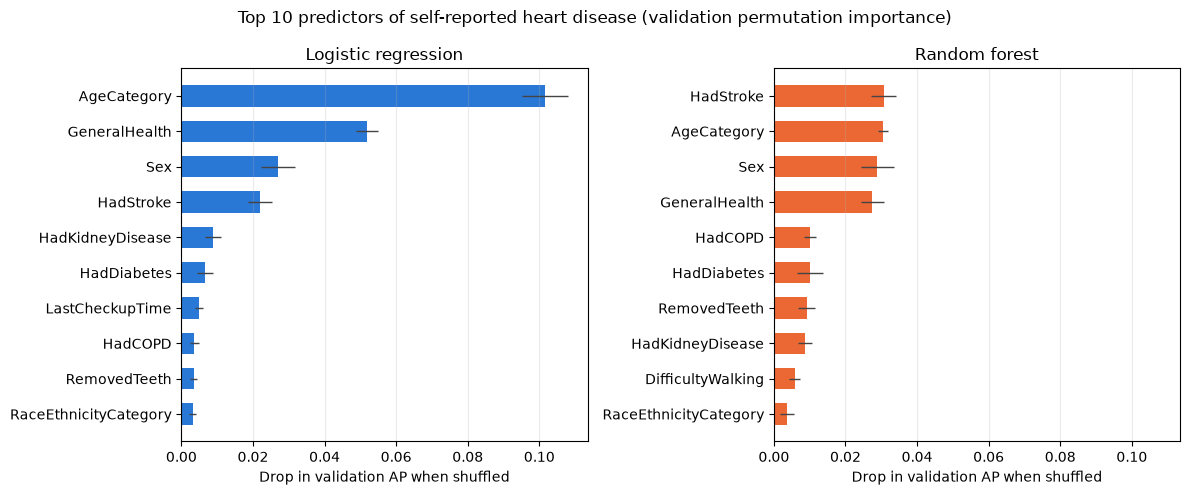

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (label, table) in zip(axes, [("Logistic regression", imp_lr), ("Random forest", imp_rf)]):
    top = table.head(10).iloc[::-1]
    ax.barh(top["feature"], top["ap_drop_mean"], xerr=top["ap_drop_sd"], color=COLORS[label],
            height=0.6, error_kw={"ecolor": "#444444", "lw": 1})
    ax.set_title(label)
    ax.set_xlabel("Drop in validation AP when shuffled")
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Top 10 predictors of self-reported heart disease (validation permutation importance)")
plt.tight_layout()
plt.savefig(FIG_DIR / "m02_permutation_importance_top10.png", dpi=300, bbox_inches="tight")
plt.show()

Build the **top-five handoff for Member 2 (Q2)**. Plan rules: use the selected model's ranking, keep only predictors with a positive mean AP drop, and show the other model's ranking next to it.

The "selected model" is the one with the higher validation AP.

In [ ]:
selected_label = max(final, key=lambda k: metrics_at_threshold(y_valid, final[k][1])["average_precision"])
other_label = [k for k in final if k != selected_label][0]
other_rank = importance[importance["model"] == other_label].set_index("feature")["rank"]

handoff = (importance[(importance["model"] == selected_label) & (importance["ap_drop_mean"] > 0)]
           .head(5)
           .assign(**{f"rank_in_{other_label.replace(' ', '_').lower()}": lambda d: d["feature"].map(other_rank)}))
handoff.to_csv(RESULTS_DIR / "top5_handoff_for_q2.csv", index=False)
print("Selected model:", selected_label)
handoff.round(4)

Selected model: Logistic regression


,model,feature,ap_drop_mean,ap_drop_sd,rank,rank_in_random_forest
0,Logistic regression,AgeCategory,0.1016,0.0064,1,2
1,Logistic regression,GeneralHealth,0.0519,0.0031,2,4
2,Logistic regression,Sex,0.0270,0.0047,3,3
3,Logistic regression,HadStroke,0.0219,0.0034,4,1
4,Logistic regression,HadKidneyDisease,0.0088,0.0022,5,8


How much do the two models' top fives overlap?

In [ ]:
top5_lr = set(imp_lr.head(5)["feature"])
top5_rf = set(imp_rf.head(5)["feature"])
print("in both top fives:", sorted(top5_lr & top5_rf))
print("only logistic regression:", sorted(top5_lr - top5_rf))
print("only random forest:", sorted(top5_rf - top5_lr))

in both top fives: ['AgeCategory', 'GeneralHealth', 'HadStroke', 'Sex']
only logistic regression: ['HadKidneyDisease']
only random forest: ['HadCOPD']


**Outcome (section 10):** both models clearly beat the baseline on the 10,000-row sample (AP 0.355 and 0.350 vs 0.090), so their rankings are meaningful.

- **Shared top four:** AgeCategory, GeneralHealth, Sex and HadStroke are in both models' top five. Logistic regression adds HadKidneyDisease; the forest adds HadCOPD.
- **Different spread:** logistic regression leans heavily on age (AP drop 0.102) and general health (0.052). The forest spreads importance more evenly (stroke 0.031, age 0.031, sex 0.029, general health 0.027). Correlated predictors can share credit, so exact positions should not be over-read.
- **Handoff to Member 2 (Q2):** the selected model is logistic regression (higher validation AP). Its top five, all with a positive importance: **AgeCategory, GeneralHealth, Sex, HadStroke, HadKidneyDisease**. Saved in `results/modelling/top5_handoff_for_q2.csv`.
- **Interpretation:** several familiar factors (BMI, PhysicalActivities, MentalHealthDays) have importance near zero. This means the model does not *need* them once age, general health and the conditions are known, perhaps because they overlap with diabetes or general health. It does **not** mean they are irrelevant to heart health. These rankings are predictive associations, not causes.
- **Next:** confirm the ranking is stable (seeds 7 and 21) before the final test.

Figure: `results/figures/m02_permutation_importance_top10.png`.

## 11. Next steps (not done in this notebook yet)

- **Ranking stability:** refit the selected settings with seeds 7 and 21 and compare the top fives (plan step 4).
- **One-row-per-duplicate-group check** on validation (plan, robustness).
- **Final test evaluation, once:** baseline and both frozen models on the test split, with the bootstrap AP difference, confusion matrices and the age/sex subgroup error table. This goes in a separate section or notebook, only after everything above is written into the decision log.